# Digital Image Processing — Week 5 · Task 1

**Grup: Nmertgules ve Iliya**

OpenCV ile renk kanalı histogramları

Renkli görüntü önce gösterilir. B, G ve R kanalları için 0–255 değerlerinin frekansları ayrı hesaplanır. Görüntü griye çevrilmez.

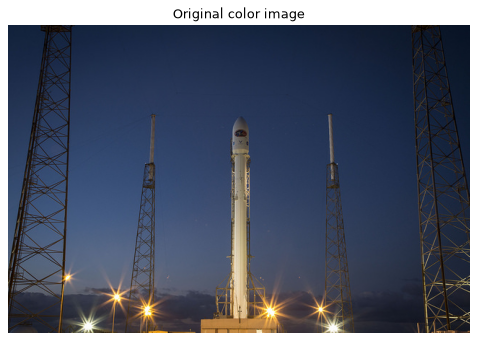

Görüntü: 640 × 427, uint8


In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Repodaki mevcut renkli fotoğrafı kullanıyoruz.
HERE = Path('week5') if Path('week5').is_dir() else Path('.')
IMAGE = HERE.parent / 'week4' / 'assets' / 'rocket.jpg'
bgr = cv2.imread(str(IMAGE), cv2.IMREAD_COLOR)
if bgr is None:
    raise FileNotFoundError(f'Görüntü okunamadı: {IMAGE}. Repoyu bütünüyle indirin.')
OUT = HERE / 'results'
OUT.mkdir(exist_ok=True)
channels = cv2.split(bgr)  # B, G, R
names = ['Blue (B)', 'Green (G)', 'Red (R)']
colors = ['blue', 'green', 'red']
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
plt.title('Original color image')
plt.axis('off')
plt.show()
print(f'Görüntü: {bgr.shape[1]} × {bgr.shape[0]}, {bgr.dtype}')


In [2]:
histograms = [cv2.calcHist([channel], [0], None, [256], [0, 256]).ravel() for channel in channels]


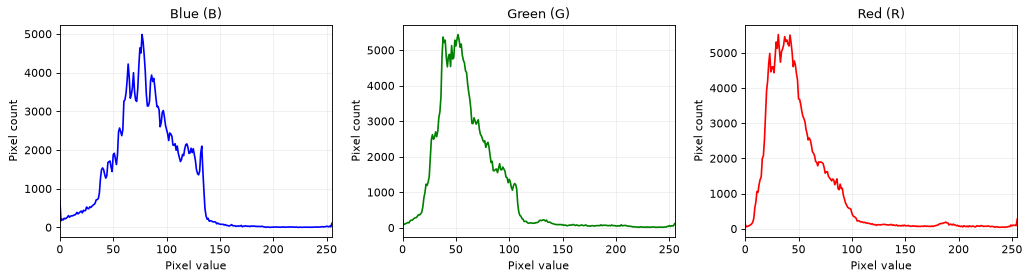

Blue (B): 256 kutu, toplam 273280 piksel
Green (G): 256 kutu, toplam 273280 piksel
Red (R): 256 kutu, toplam 273280 piksel


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, hist, name, color in zip(axes, histograms, names, colors):
    ax.plot(np.arange(256), hist, color=color)
    ax.set(title=name, xlabel='Pixel value', ylabel='Pixel count', xlim=(0, 255))
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'task1_histograms.svg')
plt.show()
for name, hist in zip(names, histograms):
    assert int(hist.sum()) == bgr.shape[0] * bgr.shape[1]
    print(f'{name}: 256 kutu, toplam {int(hist.sum())} piksel')
